# Week 8 - K-Nearest Neighbors
## Dataset: FEMA NFIP Claims

This week covers k-nearest neighbors (KNN) and the distance metrics it depends on. KNN does not fit a model in the usual sense. To classify a new claim, it finds the k training claims closest to it in feature space and predicts the share of those neighbors that paid more than $50,000. Everything therefore depends on what "closest" means, which is set by the distance metric (Euclidean, Manhattan, and others) and by how each feature is scaled before distances are measured. The number of neighbors k controls overfitting. With k = 1 the prediction copies a single neighbor, and with a very large k every claim gets close to the overall average.

The question is the same one Weeks 4 to 9 asked of the NFIP data, whether a 2017 claim paid more than $50,000 on the building, with the same 12 features and the same train and test split. KNN suits this question well, since it predicts a claim's outcome from the most similar past claims, much as an adjuster might compare a new claim with similar ones.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupShuffleSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, RocCurveDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

columns = ['yearOfLoss', 'amountPaidOnBuildingClaim', 'originalConstructionDate', 'ratedFloodZone',
           'buildingReplacementCost', 'totalBuildingInsuranceCoverage', 'waterDepth',
           'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
           'postFIRMConstructionIndicator', 'latitude', 'longitude']
df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False, usecols=columns)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Data, features, and splits

The features are recorded water depth, the logs of building replacement cost and coverage, number of floors, construction year, latitude, longitude, and indicators for elevated buildings, primary residences, post-FIRM construction, and A and V flood zones, exactly as in Weeks 4 to 9. The test set is the same 25,261 claims. Inside the training set, 20% of the claims are set aside as a validation set for the experiments, and the final settings are chosen by cross-validation on the full training set. Logistic regression and a random forest with the Week 6 settings are refit as reference points, at test ROC-AUCs of 0.779 and 0.875.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
df['logCoverage'] = np.log10(df['totalBuildingInsuranceCoverage'].clip(lower=1))
features = ['waterDepth', 'logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
            'elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
            'constructionYear', 'latitude', 'longitude', 'zoneA', 'zoneV']
data = df.dropna(subset=features).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
y = (data['amountPaidOnBuildingClaim'] > 50000).astype(int).values
X = data[features]

# Same stratified split as Weeks 4 to 6
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]

# A validation set carved out of the training claims, for watching the model grow tree by tree
fit_pos, val_pos = train_test_split(np.arange(len(train_idx)), test_size=0.2, stratify=y_train, random_state=1)
X_fit, X_val, y_fit, y_val = X_train.iloc[fit_pos], X_train.iloc[val_pos], y_train[fit_pos], y_train[val_pos]
print('Claims used:', len(data), '| share over $50,000:', round(y.mean(), 3))
print('Training claims:', len(train_idx), f'(fit {len(fit_pos)}, validation {len(val_pos)})', '| test claims:', len(test_idx))

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=400, max_features=3, min_samples_leaf=5, n_jobs=-1,
                                random_state=0).fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]
p_forest = forest.predict_proba(X_test)[:, 1]
print(f'Reference test ROC-AUC, logistic regression: {roc_auc_score(y_test, p_logit):.4f}')
print(f'Reference test ROC-AUC, Week 6 random forest settings: {roc_auc_score(y_test, p_forest):.4f}')

Claims used:

 101042 | share over $50,000: 0.532
Training claims: 75781 (fit 60624, validation 15157) | test claims: 25261


Reference test ROC-AUC, logistic regression: 0.7789
Reference test ROC-AUC, Week 6 random forest settings: 0.8752


### Feature scaling

KNN measures similarity by adding up the differences in every feature, so a feature on a larger scale counts for more. For each scaling choice, the next cell measures the share of the average squared distance between two claims that comes from each feature, and scores KNN with k = 25 and Euclidean distance on the validation claims.

KNN with k = 25 and Euclidean distance, scored on the validation claims
                Scaling  Validation ROC-AUC     Largest share of distance  Its share  Latitude and longitude share
             No scaling              0.8232              constructionYear     0.6223                        0.1016
           Standardized              0.8383     primaryResidenceIndicator     0.0833                        0.1667
                Min-max              0.8311 postFIRMConstructionIndicator     0.2837                        0.0131
Robust (median and IQR)              0.8526                    waterDepth     0.7787                        0.1934


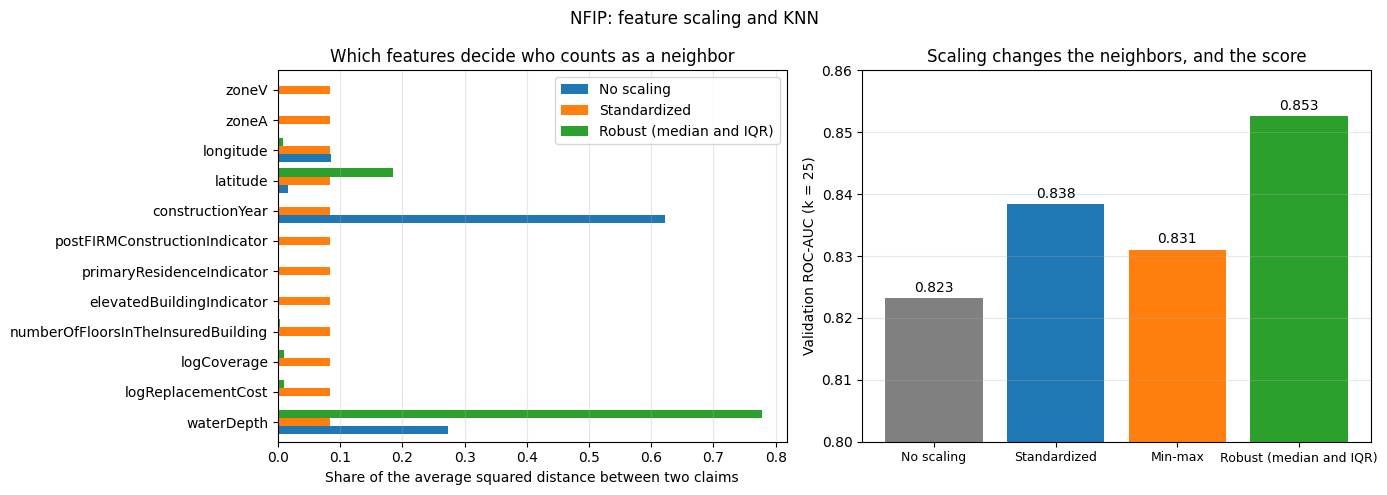

In [3]:
def val_auc(model, Xa=None, Xb=None):
    """Fit on the fit claims and return ROC-AUC on the validation claims."""
    Xa = X_fit if Xa is None else Xa
    Xb = X_val if Xb is None else Xb
    model.fit(Xa, y_fit)
    return roc_auc_score(y_val, model.predict_proba(Xb)[:, 1])


scalers = [('No scaling', None), ('Standardized', StandardScaler()), ('Min-max', MinMaxScaler()),
           ('Robust (median and IQR)', RobustScaler())]
scaling_rows, shares = [], {}
for name, scaler in scalers:
    Z = X_fit.values if scaler is None else scaler.fit_transform(X_fit)
    # Share of the average squared distance between two claims that comes from each feature
    var = Z.var(axis=0)
    shares[name] = pd.Series(var / var.sum(), index=features)
    knn = KNeighborsClassifier(n_neighbors=25)
    model = knn if scaler is None else make_pipeline(scaler, knn)
    scaling_rows.append({'Scaling': name, 'Validation ROC-AUC': val_auc(model),
                         'Largest share of distance': shares[name].idxmax(),
                         'Its share': shares[name].max(),
                         'Latitude and longitude share': shares[name][['latitude', 'longitude']].sum()})
scaling = pd.DataFrame(scaling_rows)
print('KNN with k = 25 and Euclidean distance, scored on the validation claims')
print(scaling.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
share_table = pd.DataFrame(shares)[['No scaling', 'Standardized', 'Robust (median and IQR)']]
share_table.plot.barh(ax=axes[0], width=0.8)
axes[0].set_xlabel('Share of the average squared distance between two claims')
axes[0].set_title('Which features decide who counts as a neighbor')
axes[0].grid(alpha=0.3, axis='x')
axes[1].bar(scaling['Scaling'], scaling['Validation ROC-AUC'], color=['gray', 'C0', 'C1', 'C2'])
axes[1].set_ylim(0.80, 0.86)
axes[1].set_ylabel('Validation ROC-AUC (k = 25)')
axes[1].set_title('Scaling changes the neighbors, and the score')
for i, v in enumerate(scaling['Validation ROC-AUC']):
    axes[1].text(i, v + 0.001, f'{v:.3f}', ha='center')
axes[1].tick_params(axis='x', labelsize=9)
axes[1].grid(alpha=0.3, axis='y')
fig.suptitle('NFIP: feature scaling and KNN')
plt.tight_layout()
plt.show()

Without scaling, construction year supplies 62% of the squared distance and water depth 27%, because years and depth units have far larger spreads than the 0/1 indicators or the log costs. The neighbors are then mostly claims built in the same year with a similar depth, and the validation ROC-AUC is 0.823. Standardizing gives every feature an equal 8.3% and scores 0.838. Min-max scaling (0.831) again suffers from extremes, since the claim in Guam squeezes longitude and a depth of 610 squeezes water depth, which leaves location with 1.3% of the distance. Robust scaling does best (0.853). It divides each feature by its interquartile range, and water depth has a narrow middle range around its median of 1 with a long tail, so depth ends up supplying 78% of the distance and latitude another 18%. That is close to what the earlier models found, since depth and location were among the strongest predictors in Weeks 6 and 9. The best scaling for KNN is the one that weights features by how much they matter, which no standard scaler knows.

### The number of neighbors

The next cell standardizes the features and scores k from 1 to 500 on the training claims, where each claim counts as its own neighbor, and on the validation claims.

  k  Training ROC-AUC  Validation ROC-AUC     Gap
  1            0.9995              0.7091  0.2905
  3            0.9335              0.7865  0.1470
  5            0.9069              0.8102  0.0967
 10            0.8810              0.8271  0.0539
 15            0.8710              0.8342  0.0368
 25            0.8611              0.8383  0.0227
 50            0.8484              0.8396  0.0089
 75            0.8410              0.8377  0.0033
100            0.8365              0.8362  0.0003
150            0.8306              0.8328 -0.0022
200            0.8261              0.8303 -0.0041
300            0.8186              0.8257 -0.0071
500            0.8100              0.8190 -0.0091
Best k on the validation claims: 50


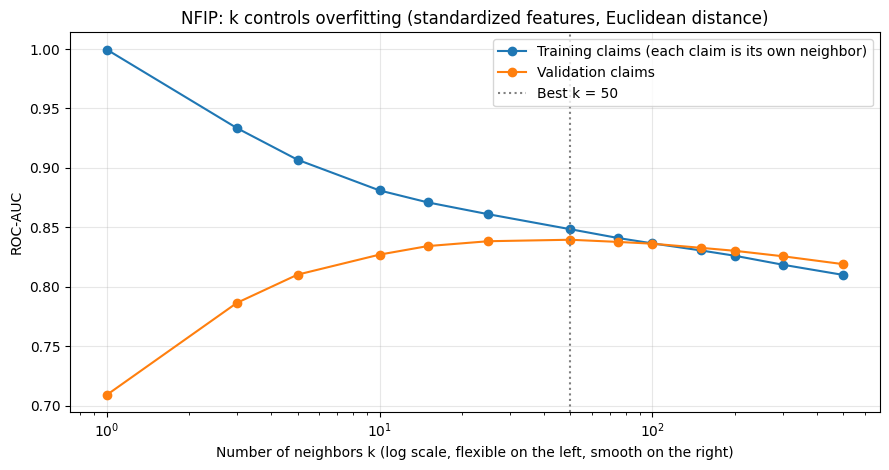

In [4]:
scaler = StandardScaler().fit(X_fit)
Z_fit, Z_val = scaler.transform(X_fit), scaler.transform(X_val)
sample = np.random.RandomState(0).choice(len(y_fit), 10000, replace=False)
k_values = [1, 3, 5, 10, 15, 25, 50, 75, 100, 150, 200, 300, 500]
k_rows = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k).fit(Z_fit, y_fit)
    k_rows.append({'k': k,
                   'Training ROC-AUC': roc_auc_score(y_fit[sample], knn.predict_proba(Z_fit[sample])[:, 1]),
                   'Validation ROC-AUC': roc_auc_score(y_val, knn.predict_proba(Z_val)[:, 1])})
k_table = pd.DataFrame(k_rows)
k_table['Gap'] = k_table['Training ROC-AUC'] - k_table['Validation ROC-AUC']
best_k = int(k_table.loc[k_table['Validation ROC-AUC'].idxmax(), 'k'])
print(k_table.round(4).to_string(index=False))
print('Best k on the validation claims:', best_k)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(k_table['k'], k_table['Training ROC-AUC'], marker='o', label='Training claims (each claim is its own neighbor)')
ax.plot(k_table['k'], k_table['Validation ROC-AUC'], marker='o', label='Validation claims')
ax.axvline(best_k, color='gray', linestyle=':', label=f'Best k = {best_k}')
ax.set_xscale('log')
ax.set_xlabel('Number of neighbors k (log scale, flexible on the left, smooth on the right)')
ax.set_ylabel('ROC-AUC')
ax.set_title('NFIP: k controls overfitting (standardized features, Euclidean distance)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The curve shows overfitting directly. With k = 1 each training claim is its own nearest neighbor, so the training ROC-AUC is nearly perfect (0.9995), while validation is only 0.709, a gap of 0.29. As k grows the training score falls and the validation score rises until they meet. Validation peaks at k = 50 (0.840), where the gap is 0.009, and then declines slowly, since a neighborhood of hundreds of claims averages over buildings that are not alike. Past k = 100 the training score drops below the validation score, a sign of underfitting.

### Distance metrics and neighbor weighting

The Minkowski distance of order p is the p-th root of the sum of each absolute feature difference raised to the power p. With p = 2 it is the Euclidean distance, with p = 1 it is the Manhattan distance, and as p grows it approaches the Chebyshev distance, which only counts the single largest difference. Cosine distance compares only the direction of two standardized claims from the center of the data. The next cell compares these metrics at k = 50, each with uniform weights and with distance weights (closer neighbors count more), and measures how often each metric picks the same single nearest neighbor as Euclidean distance.

Standardized features, k = 50, scored on the validation claims
Weights                  distance  uniform
Metric                                    
Euclidean (p = 2)          0.8438   0.8396
Manhattan (p = 1)          0.8502   0.8463
Minkowski p = 4            0.8407   0.8363
Chebyshev (largest gap)    0.8381   0.8333
Cosine (angle only)        0.8413   0.8398



Share of 3,000 validation claims whose single nearest neighbor matches the Euclidean one:
  Euclidean (p = 2)          1.000
  Manhattan (p = 1)          0.748
  Minkowski p = 4            0.863
  Chebyshev (largest gap)    0.713
  Cosine (angle only)        0.911


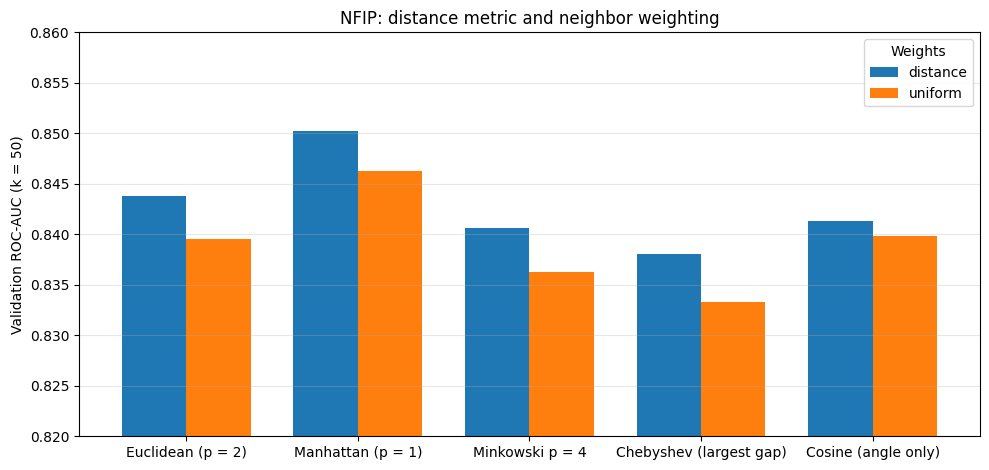

In [5]:
metrics = [('Euclidean (p = 2)', dict(metric='euclidean')), ('Manhattan (p = 1)', dict(metric='manhattan')),
           ('Minkowski p = 4', dict(metric='minkowski', p=4)), ('Chebyshev (largest gap)', dict(metric='chebyshev')),
           ('Cosine (angle only)', dict(metric='cosine'))]
metric_rows = []
for name, params in metrics:
    for weights in ['uniform', 'distance']:
        knn = KNeighborsClassifier(n_neighbors=best_k, weights=weights, n_jobs=4, **params).fit(Z_fit, y_fit)
        metric_rows.append({'Metric': name, 'Weights': weights,
                            'Validation ROC-AUC': roc_auc_score(y_val, knn.predict_proba(Z_val)[:, 1])})
metric_table = pd.DataFrame(metric_rows)
print(f'Standardized features, k = {best_k}, scored on the validation claims')
print(metric_table.pivot(index='Metric', columns='Weights', values='Validation ROC-AUC')
      .loc[[m for m, _ in metrics]].round(4).to_string())

# How often two metrics agree on a claim's nearest neighbor
nn = {name: KNeighborsClassifier(n_neighbors=1, **params).fit(Z_fit, y_fit).kneighbors(Z_val[:3000], 1,
                                                                                    return_distance=False)[:, 0]
      for name, params in metrics}
print('\nShare of 3,000 validation claims whose single nearest neighbor matches the Euclidean one:')
for name in nn:
    print(f'  {name:26s} {np.mean(nn[name] == nn["Euclidean (p = 2)"]):.3f}')

fig, ax = plt.subplots(figsize=(10, 4.8))
pivot = metric_table.pivot(index='Metric', columns='Weights', values='Validation ROC-AUC').loc[[m for m, _ in metrics]]
pivot.plot.bar(ax=ax, rot=0, width=0.75)
ax.set_ylim(0.82, 0.86)
ax.set_ylabel(f'Validation ROC-AUC (k = {best_k})')
ax.set_xlabel('')
ax.set_title('NFIP: distance metric and neighbor weighting')
ax.legend(title='Weights')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Manhattan distance with distance weights does best (0.850), followed by Euclidean (0.844), cosine (0.841), Minkowski with p = 4 (0.841), and Chebyshev (0.838). Distance weighting helps every metric, by 0.002 to 0.005. As for Storm Events, the smaller p is, the better. With p = 1 a large difference in one feature, such as a deep flood against a shallow one, adds to the distance in proportion, while larger p lets that one difference dominate. The metrics also disagree about who the nearest neighbor is. Manhattan distance picks a different nearest neighbor than Euclidean distance for 25% of claims and Chebyshev for 29%, so the metric changes which past claims each prediction is built from.

### The curse of dimensionality and feature weighting

KNN treats every feature in the distance as equally important. The next cell tests both sides of that. It adds pure-noise features, each a standard normal variable with no relation to the target, and then goes the other way and multiplies standardized latitude and longitude by a weight before measuring distance.

 Pure-noise features added  Total features  Validation ROC-AUC
                         0              12              0.8438
                         2              14              0.8197
                         5              17              0.8036
                        10              22              0.7980
                        20              32              0.7812
                        40              52              0.7613



 Weight on latitude and longitude  Validation ROC-AUC
                                0              0.8011
                                1              0.8502
                                2              0.8527
                                3              0.8541
                                5              0.8554
                                8              0.8563
                               12              0.8566


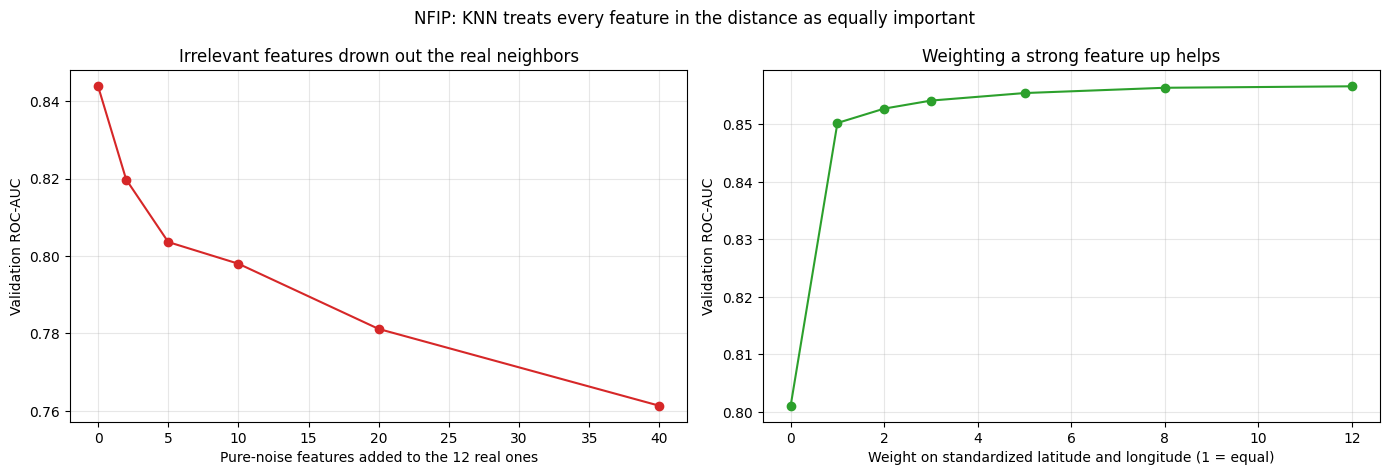

In [6]:
rng = np.random.RandomState(0)
noise_rows = []
for n_noise in [0, 2, 5, 10, 20, 40]:
    A = np.hstack([Z_fit, rng.randn(len(Z_fit), n_noise)])
    B = np.hstack([Z_val, rng.randn(len(Z_val), n_noise)])
    knn = KNeighborsClassifier(n_neighbors=best_k, weights='distance').fit(A, y_fit)
    noise_rows.append({'Pure-noise features added': n_noise, 'Total features': A.shape[1],
                       'Validation ROC-AUC': roc_auc_score(y_val, knn.predict_proba(B)[:, 1])})
noise_table = pd.DataFrame(noise_rows)
print(noise_table.round(4).to_string(index=False))

# The other direction, giving the most useful features more weight in the distance
loc_cols = [features.index('latitude'), features.index('longitude')]
weight_rows = []
for w in [0, 1, 2, 3, 5, 8, 12]:
    W = np.ones(len(features))
    W[loc_cols] = w
    knn = KNeighborsClassifier(n_neighbors=best_k, weights='distance', metric='manhattan').fit(Z_fit * W, y_fit)
    weight_rows.append({'Weight on latitude and longitude': w,
                        'Validation ROC-AUC': roc_auc_score(y_val, knn.predict_proba(Z_val * W)[:, 1])})
weight_table = pd.DataFrame(weight_rows)
print()
print(weight_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(noise_table['Pure-noise features added'], noise_table['Validation ROC-AUC'], marker='o', color='C3')
axes[0].set_xlabel('Pure-noise features added to the 12 real ones')
axes[0].set_ylabel('Validation ROC-AUC')
axes[0].set_title('Irrelevant features drown out the real neighbors')
axes[0].grid(alpha=0.3)
axes[1].plot(weight_table['Weight on latitude and longitude'], weight_table['Validation ROC-AUC'], marker='o', color='C2')
axes[1].set_xlabel('Weight on standardized latitude and longitude (1 = equal)')
axes[1].set_ylabel('Validation ROC-AUC')
axes[1].set_title('Weighting a strong feature up helps')
axes[1].grid(alpha=0.3)
fig.suptitle('NFIP: KNN treats every feature in the distance as equally important')
plt.tight_layout()
plt.show()

Noise features hurt quickly. Two of them lower validation ROC-AUC from 0.844 to 0.820, five to 0.804, and forty to 0.761, close to logistic regression. Each noise feature adds random distance between every pair of claims, so true neighbors are pushed apart and unrelated claims pulled in. This is the curse of dimensionality. In many dimensions all points are roughly equally far apart, and the nearest neighbors stop being meaningfully near. Weighting goes the other way. With Manhattan distance and distance weights, dropping location (weight 0) costs 0.049, while tripling its weight raises the score from 0.850 to 0.854 and a weight of 12 raises it to 0.857, with the gains leveling off. KNN only uses the features well when the analyst tells it which ones matter, through the choice of features and their scaling.

### Measuring distance on the map

Latitude and longitude are angles on a sphere, and a degree of longitude covers less ground the farther north a claim is. The haversine distance measures the great-circle distance directly. The next cell compares location-only KNN under haversine and Euclidean distance, and then KNN without location and with all features.

In [7]:
cells_fit = X_fit[['latitude', 'longitude']].drop_duplicates()
print('Distinct latitude and longitude pairs among', len(X_fit), 'fit claims:', len(cells_fit))
print('Coordinates are rounded to 0.1 degree, so most claims share their exact location with others')

geo_rows = []
R_fit, R_val = np.radians(X_fit[['latitude', 'longitude']].values), np.radians(X_val[['latitude', 'longitude']].values)
geo = [('Location only, haversine (great-circle km)', KNeighborsClassifier(n_neighbors=best_k, metric='haversine',
                                                                             algorithm='ball_tree'), R_fit, R_val),
       ('Location only, Euclidean on raw degrees', KNeighborsClassifier(n_neighbors=best_k),
        X_fit[['latitude', 'longitude']].values, X_val[['latitude', 'longitude']].values)]
no_loc = [i for i in range(len(features)) if i not in loc_cols]
geo += [('Building and flood features, no location', KNeighborsClassifier(n_neighbors=best_k), Z_fit[:, no_loc], Z_val[:, no_loc]),
        ('All 12 features', KNeighborsClassifier(n_neighbors=best_k), Z_fit, Z_val)]
for name, knn, A, B in geo:
    knn.fit(A, y_fit)
    geo_rows.append({'Neighbors found by': name, 'Validation ROC-AUC': roc_auc_score(y_val, knn.predict_proba(B)[:, 1])})
print(pd.DataFrame(geo_rows).round(4).to_string(index=False))

# How different a degree of longitude is from a degree of latitude at these latitudes
print('\nKilometers per degree of longitude at the median claim latitude '
      f'({X_fit["latitude"].median():.1f}): {111.32 * np.cos(np.radians(X_fit["latitude"].median())):.1f}, '
      'against about 110.6 for a degree of latitude')

Distinct latitude and longitude pairs among

 60624 fit claims: 2855
Coordinates are rounded to 0.1 degree, so most claims share their exact location with others


                        Neighbors found by  Validation ROC-AUC
Location only, haversine (great-circle km)              0.7776
   Location only, Euclidean on raw degrees              0.7777
  Building and flood features, no location              0.8023
                           All 12 features              0.8396

Kilometers per degree of longitude at the median claim latitude (29.8): 96.6, against about 110.6 for a degree of latitude


The fit claims sit at only 2,855 distinct locations, because the redacted coordinates are rounded to 0.1 degree. Location alone reaches a validation ROC-AUC of 0.778, and the haversine distance makes no difference (0.7776 against 0.7777). Most claims are near 30 degrees north, where a degree of longitude is 96.6 km against 110.6 km for latitude, and neighbors are close enough that this distortion barely changes their order. Building and flood features without location reach 0.802, and all features together reach 0.840, so location adds information the building features do not carry, mostly which storm hit, as in every model since Week 4.

### Tuning everything together

The last step searches the scaler (standard or robust), k, the metric (Euclidean or Manhattan), and the weighting together with `GridSearchCV`, 40 combinations scored by 5-fold cross-validation on the full training set.

In [8]:
pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
param_grid = {'scale': [StandardScaler(), RobustScaler()],
              'knn__n_neighbors': [25, 50, 75, 100, 150],
              'knn__metric': ['euclidean', 'manhattan'],
              'knn__weights': ['uniform', 'distance']}
search = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=6)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Grid search of {len(search.cv_results_["params"])} settings x 5 folds took {time.time() - t0:.0f} seconds')
res = pd.DataFrame(search.cv_results_)
res['scale'] = res['param_scale'].astype(str).str.replace('()', '', regex=False)
cols = ['scale', 'param_knn__n_neighbors', 'param_knn__metric', 'param_knn__weights', 'mean_test_score', 'std_test_score']
print(res.sort_values('rank_test_score')[cols].head(8).round(4).to_string(index=False))
print('\nBest settings:', {k: (str(v) if k == 'scale' else v) for k, v in search.best_params_.items()})
print(f'Best CV ROC-AUC: {search.best_score_:.4f}')
print(f'Spread of CV ROC-AUC across all settings: {res["mean_test_score"].min():.4f} to {res["mean_test_score"].max():.4f}')

Grid search of 40 settings x 5 folds took 269 seconds
       scale  param_knn__n_neighbors param_knn__metric param_knn__weights  mean_test_score  std_test_score
RobustScaler                      50         manhattan           distance           0.8601          0.0018
RobustScaler                      75         manhattan           distance           0.8593          0.0021
RobustScaler                     100         manhattan           distance           0.8584          0.0021
RobustScaler                      25         manhattan           distance           0.8581          0.0018
RobustScaler                     150         manhattan           distance           0.8568          0.0021
RobustScaler                      50         euclidean           distance           0.8566          0.0020
RobustScaler                      50         manhattan            uniform           0.8561          0.0020
RobustScaler                      25         manhattan            uniform           0.8557

The best setting is robust scaling, k = 50, Manhattan distance, and distance weights, at a CV ROC-AUC of 0.860. The top five settings all use robust scaling, Manhattan distance, and distance weights, with k from 25 to 150, and they fall within 0.003 of each other, so the scaler and the metric matter more than the exact k. The full range across the 40 settings is 0.830 to 0.860.

### Final evaluation on the held-out test set

Test claims: 25261
                                        Model  Accuracy  Balanced acc.     F1  Log loss  ROC-AUC
                               Majority class    0.5323         0.5000 0.6948    0.6911   0.5000
                          Logistic regression    0.7145         0.7056 0.7586    0.5771   0.7789
              Random forest (Week 6 settings)    0.7856         0.7833 0.8027    0.4388   0.8752
KNN, default (k = 5, Euclidean, standardized)    0.7440         0.7410 0.7659    0.9680   0.8133
                                   KNN, tuned    0.7725         0.7677 0.7973    0.4817   0.8611

Seconds to predict the test claims, tuned KNN: 4.3 | random forest: 0.2


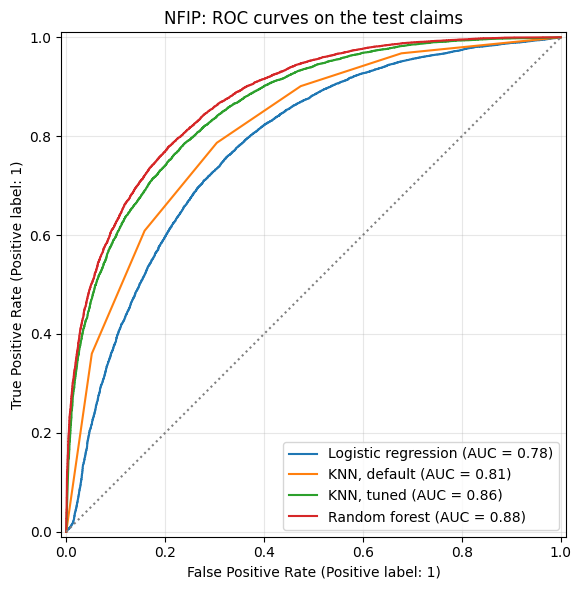

In [9]:
def scores(name, prob):
    pred = (prob >= 0.5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Balanced acc.': balanced_accuracy_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'Log loss': log_loss(y_test, np.clip(prob, 1e-6, 1 - 1e-6)),
            'ROC-AUC': roc_auc_score(y_test, prob)}


best = search.best_estimator_
default_knn = make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(X_train, y_train)
t0 = time.time()
p_best = best.predict_proba(X_test)[:, 1]
knn_seconds = time.time() - t0
t0 = time.time()
forest.predict_proba(X_test)
forest_seconds = time.time() - t0
p_default = default_knn.predict_proba(X_test)[:, 1]
final = pd.DataFrame([scores('Majority class', np.full(len(y_test), y_train.mean())),
                      scores('Logistic regression', p_logit),
                      scores('Random forest (Week 6 settings)', p_forest),
                      scores('KNN, default (k = 5, Euclidean, standardized)', p_default),
                      scores('KNN, tuned', p_best)])
print('Test claims:', len(y_test))
print(final.round(4).to_string(index=False))
print(f'\nSeconds to predict the test claims, tuned KNN: {knn_seconds:.1f} | random forest: {forest_seconds:.1f}')

fig, ax = plt.subplots(figsize=(7, 6))
for name, prob in [('Logistic regression', p_logit), ('KNN, default', p_default), ('KNN, tuned', p_best),
                   ('Random forest', p_forest)]:
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
ax.set_title('NFIP: ROC curves on the test claims')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The tuned KNN reaches a test ROC-AUC of 0.861, with an accuracy of 0.773, a balanced accuracy of 0.768, an F1 of 0.797, and a log loss of 0.482. That is well ahead of logistic regression (0.779) and default KNN (0.813), but behind the random forest (0.875) and Week 9's gradient boosting (0.880). Default KNN has a log loss of 0.968, worse than predicting the base rate (0.691), because with 5 neighbors many claims get a probability of exactly 0 or 1, and confident mistakes are heavily penalized. KNN is also slow at prediction time, since every prediction searches the training claims. It took 4.3 seconds to score the test claims, against 0.2 seconds for the random forest.

### Is the model memorizing neighborhoods?

KNN predicts from the nearest claims, and with rounded coordinates the nearest claims are often at the same location. The next cell repeats the location check from earlier weeks, holding out whole 0.1-degree location cells so that no test claim has a neighbor at its own location.

In [10]:
cells_id = data['latitude'].round(1).astype(str) + '_' + data['longitude'].round(1).astype(str)
g_train, g_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, cells_id))
best_params = {k: v for k, v in best.get_params().items() if k.startswith('knn__')}
rows = []
for name, model, p_random in [
        ('KNN, k = 5', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), None),
        ('KNN, tuned', Pipeline([('scale', type(best.named_steps['scale'])()), ('knn', KNeighborsClassifier())]).set_params(**best_params), p_best),
        ('Random forest (Week 6 settings)', RandomForestClassifier(n_estimators=400, max_features=3, min_samples_leaf=5,
                                                                   n_jobs=-1, random_state=0), p_forest)]:
    if p_random is None:
        p_random = model.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    model.fit(X.iloc[g_train], y[g_train])
    rows.append({'Model': name, 'Random split AUC': roc_auc_score(y_test, p_random),
                 'Location-cell split AUC': roc_auc_score(y[g_test], model.predict_proba(X.iloc[g_test])[:, 1])})
loc = pd.DataFrame(rows)
loc['Drop'] = loc['Random split AUC'] - loc['Location-cell split AUC']
print('Location cells:', cells_id.nunique(), '| shared between train and test:',
      len(set(cells_id.iloc[g_train]) & set(cells_id.iloc[g_test])))
print(loc.round(4).to_string(index=False))

Location cells: 3580 | shared between train and test: 0
                          Model  Random split AUC  Location-cell split AUC   Drop
                     KNN, k = 5            0.8133                   0.7918 0.0215
                     KNN, tuned            0.8611                   0.8452 0.0159
Random forest (Week 6 settings)            0.8752                   0.8664 0.0089


Holding out whole location cells lowers tuned KNN from 0.861 to 0.845, a drop of 0.016, and KNN with k = 5 drops 0.022. Both drops are larger than the random forest's 0.009, so KNN leans on neighbors at the same location more than the forest does, and the smaller the neighborhood, the more it leans. Even so, tuned KNN keeps most of its accuracy on unseen areas, so it is learning from similar buildings and floods, not only from claims next door.

## Discussion

### Overfitting

KNN's overfitting is controlled by k. With k = 1 the training score is 0.9995 and the validation score 0.709, and the gap closes steadily as k grows, to 0.009 at the chosen k = 50. Cross-validation chose k on data the model was not fit on, and the test set was used once at the end. Distance weighting let a larger neighborhood keep most of the benefit of its closest members, and the location-cell check showed that the tuned model holds up on areas it never saw (a drop of 0.016). The noise experiment showed a second kind of overfitting specific to KNN. Every feature added to the distance adds variance to who counts as a neighbor, so a model with irrelevant features can do worse even with the best k.

### Metrics and hyperparameter tuning

ROC-AUC was the main metric, as in Weeks 4 to 9, since it measures how well the model ranks large claims above smaller ones without depending on a cutoff. Log loss showed how badly small neighborhoods handle probabilities. The hyperparameters were tuned together by a 5-fold grid search, and each has a meaning for this problem.

- **k = 50** means each claim is judged by the 50 most similar past claims.
- **Manhattan distance** adds up the differences feature by feature, so similarity is judged across all features instead of being dominated by the largest difference.
- **Distance weights** let the most similar of those 50 claims count the most.
- **Robust scaling** sets how much each feature counts in the distance, and it effectively weights water depth and location most heavily, which suits this problem.

### Expected or unexpected

I expected standardization to be the best scaling, as it was for logistic regression in Week 4, but robust scaling beat it by 0.014 because it happened to give water depth most of the weight. I also expected the haversine distance to matter for location, and it did not. The size of the curse of dimensionality was surprising. Only two noise features cost 0.024, more than the difference between most metrics. KNN finishing behind the random forest was expected, since a forest learns which features matter while KNN has to be told.

### How EDA helped

EDA explained each of the scaling results. The extreme water depths (up to 610 against a median of 1) and the claim in Guam, both found in earlier weeks, are why min-max scaling lost location and depth. The skew in replacement cost and coverage found in Module B is why they enter as logs, which keeps a few very expensive buildings from setting every distance. The rounding of coordinates to 0.1 degree, seen here in the count of 2,855 distinct locations, is why the location-cell check matters so much for KNN.

### External sources

- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
- scikit-learn User Guide, "Nearest Neighbors," including the KD tree and ball tree algorithms: https://scikit-learn.org/stable/modules/neighbors.html
- scikit-learn API reference, `DistanceMetric`, which lists the Minkowski family, Chebyshev, and haversine distances: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.DistanceMetric.html
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.), Section 2.2.3 on K-nearest neighbors and the bias and variance trade-off.

### Conclusions

Tuned KNN predicts whether a 2017 NFIP claim paid more than $50,000 with a test ROC-AUC of 0.861, ahead of logistic regression (0.779) but behind the random forest (0.875) and gradient boosting (0.880). For KNN the decisive choices were about distance, not k. Scaling changed the validation score by 0.030 and the choice of metric by 0.012, irrelevant features could cost far more, and the best results came from settings that gave the strongest features, water depth and location, the most weight in the distance.

For Milestone Two and the Capstone, KNN is useful less as a final model than as an interpretable one, since each prediction can be explained by listing the most similar past claims. Its results also confirm the main finding of earlier weeks, that water depth and the storm, through location, drive claim severity more than any other feature.